# 4 — Risk quantification : calibrage des PD (chapitre 8)

Les notebooks précédents ont construit, pour chaque segment, un score qui **classe** les clients du plus risqué au moins risqué, puis des classes homogènes de risque (CHR). Ce notebook passe de la **différenciation** du risque à sa **quantification** : attribuer à chaque CHR une **probabilité de défaut (PD)** chiffrée, qui servira au calcul des exigences en fonds propres.

Le notebook rassemble automatiquement les CHR de **tous les segments disponibles** (fichiers `base_chr_{segment}.parquet` produits par le notebook 3) : il traite aujourd'hui SB et accueillera SA et SM sans modification.

**Démarche :**
1. **Calibrage** (8.5) : plusieurs méthodes d'estimation de la PD de chaque classe sont estimées sur l'apprentissage.
2. **Vérification** (8.6) : chaque méthode est confrontée aux défauts observés sur le test (diagramme de calibration, score de Brier et décomposition de Murphy, test de Jeffreys).
3. **PD réglementaire** (8.4, 8.7) : la PD de la méthode retenue, réestimée sur l'ensemble des données, est majorée d'une **marge de prudence (MoC)** couvrant les faiblesses des données (absence de cycle complet) et l'erreur d'estimation, puis soumise au plancher réglementaire.
4. **Échelle maître** (7.5) : chaque CHR de chaque segment est rattachée à un grade d'une échelle de PD commune.

**Pourquoi une fréquence observée ne suffit pas (8.2).** Le taux de défaut d'une classe sur une période donnée est une mesure bruitée (peu de défauts dans les meilleures classes) et dépendante de la conjoncture de la période. La PD réglementaire doit refléter un **niveau moyen de long terme** (Long Run Average, LRA, approche Through-the-Cycle, 8.3-8.4) et intégrer une prudence proportionnée aux incertitudes.

In [1]:
# Cellule 1 — chargement des CHR de tous les segments disponibles
from pathlib import Path
import matplotlib.pyplot as plt
import polars as pl
from utils import calibrage, exploration

pl.Config.set_tbl_rows(-1); pl.Config.set_tbl_cols(-1); pl.Config.set_tbl_width_chars(200)
pl.Config.set_tbl_hide_column_data_types(True)

TARGET, DATE = "ddefaut_ndb", "datdelhis"
fichiers = sorted(Path("data/processed").glob("base_chr_*.parquet"))
base = pl.concat([pl.read_parquet(f) for f in fichiers], how="diagonal_relaxed")
SEGMENTS = sorted(base["segment"].unique().to_list())
print("segments disponibles :", SEGMENTS)
print(base.group_by("segment", "echantillon").agg(n=pl.len(), n_defaut=pl.col(TARGET).sum(),
                                                 taux=pl.col(TARGET).mean()).sort("segment", "echantillon"))

segments disponibles : ['SB']
shape: (2, 5)
┌─────────┬─────────────┬───────┬──────────┬─────────┐
│ segment ┆ echantillon ┆ n     ┆ n_defaut ┆ taux    │
╞═════════╪═════════════╪═══════╪══════════╪═════════╡
│ SB      ┆ test        ┆ 37996 ┆ 470.0    ┆ 0.01237 │
│ SB      ┆ train       ┆ 88629 ┆ 1091.0   ┆ 0.01231 │
└─────────┴─────────────┴───────┴──────────┴─────────┘


## 4.1 Méthodes de calibrage (8.4, 8.5)

Pour chaque segment, la PD de chaque CHR est estimée sur l'apprentissage selon cinq méthodes :

| Méthode | Principe | Intérêt / limite |
|---|---|---|
| **Fréquence observée** | taux de défaut de la classe sur la période | simple ; sensible au bruit dans les classes à peu de défauts |
| **Moyenne des taux mensuels** | moyenne des quatre taux mensuels de la classe | chaque mois pèse autant : meilleure approximation d'une moyenne dans le temps disponible sur 4 mois |
| **Recalibration logistique** | régression du défaut sur le score, PD moyenne de la classe | lisse les PD le long du score ; suppose une relation logistique |
| **Régression isotone** | ajustement monotone non paramétrique du défaut sur le score | garantit la monotonie sans hypothèse de forme |
| **Approche bayésienne (crédibilité)** | taux observé combiné à la PD du modèle, utilisée comme a priori avec un poids de 1 000 observations | stabilise les classes à peu de défauts en les rapprochant de la PD du modèle |

In [2]:
# Cellule 2 — PD de chaque CHR selon les cinq méthodes, estimées sur l'apprentissage
tables_calibrage = {}
for seg in SEGMENTS:
    train_s = base.filter((pl.col("segment") == seg) & (pl.col("echantillon") == "train"))
    tables_calibrage[seg] = calibrage.pd_par_methode(train_s, TARGET, DATE, poids_prior=1000)
    print(f"=== {seg}"); print(tables_calibrage[seg])

=== SB
shape: (5, 9)
┌─────┬───────┬──────────┬───────────┬───────────┬───────────────────┬────────────┬──────────┬──────────┐
│ chr ┆ n     ┆ n_defaut ┆ pd_modele ┆ frequence ┆ moyenne_mensuelle ┆ logistique ┆ isotone  ┆ bayesien │
╞═════╪═══════╪══════════╪═══════════╪═══════════╪═══════════════════╪════════════╪══════════╪══════════╡
│ 1   ┆ 47221 ┆ 23.0     ┆ 0.000881  ┆ 0.000487  ┆ 0.000487          ┆ 0.000827   ┆ 0.000487 ┆ 0.000495 │
│ 2   ┆ 23669 ┆ 97.0     ┆ 0.004425  ┆ 0.004098  ┆ 0.004096          ┆ 0.004221   ┆ 0.004098 ┆ 0.004111 │
│ 3   ┆ 5837  ┆ 93.0     ┆ 0.012901  ┆ 0.015933  ┆ 0.015911          ┆ 0.012425   ┆ 0.015798 ┆ 0.015489 │
│ 4   ┆ 5725  ┆ 187.0    ┆ 0.029653  ┆ 0.032664  ┆ 0.032656          ┆ 0.028808   ┆ 0.032611 ┆ 0.032216 │
│ 5   ┆ 6177  ┆ 691.0    ┆ 0.117149  ┆ 0.111867  ┆ 0.112017          ┆ 0.115685   ┆ 0.112043 ┆ 0.112603 │
└─────┴───────┴──────────┴───────────┴───────────┴───────────────────┴────────────┴──────────┴──────────┘


## 4.2 Vérification du calibrage sur le test (8.6)

Chaque méthode est confrontée aux défauts observés sur le test, qui n'a servi à aucune estimation :
- **diagramme de calibration** : taux de défaut observé de chaque classe (avec son intervalle de confiance) contre la PD calibrée ; un calibrage parfait place les points sur la diagonale ;
- **score de Brier** = moyenne de (PD − défaut)² ; sa **décomposition de Murphy** sépare la **fiabilité** (écart entre PD et taux observé, 0 = calibrage parfait), la **résolution** (capacité des classes à séparer des risques différents) et l'**incertitude** (propre à l'échantillon) : Brier = fiabilité − résolution + incertitude. Les méthodes partageant les mêmes classes ont la même résolution : c'est la fiabilité qui les départage ;
- **test de Jeffreys** par classe (usage des autorités de supervision pour valider les PD) : la p-value mesure la compatibilité des défauts observés avec la PD ; une p-value inférieure à 5 % indique une **PD sous-estimée**.

=== SB — Brier et décomposition de Murphy (test)
shape: (5, 5)
┌───────────────────┬──────────┬───────────┬────────────┬─────────────┐
│ methode           ┆ brier    ┆ fiabilite ┆ resolution ┆ incertitude │
╞═══════════════════╪══════════╪═══════════╪════════════╪═════════════╡
│ frequence         ┆ 0.011492 ┆ 0.000005  ┆ 0.000729   ┆ 0.012217    │
│ moyenne_mensuelle ┆ 0.011492 ┆ 0.000005  ┆ 0.000729   ┆ 0.012217    │
│ isotone           ┆ 0.011493 ┆ 0.000005  ┆ 0.000729   ┆ 0.012217    │
│ bayesien          ┆ 0.011493 ┆ 0.000006  ┆ 0.000729   ┆ 0.012217    │
│ logistique        ┆ 0.011502 ┆ 0.000014  ┆ 0.000729   ┆ 0.012217    │
└───────────────────┴──────────┴───────────┴────────────┴─────────────┘
shape: (5, 14)
┌─────┬───────┬──────────┬──────────────┬───────────┬──────────────────┬────────────┬──────────┬──────────┬──────────────────┬──────────────────┬──────────────────┬─────────────────┬─────────────────┐
│ chr ┆ n     ┆ n_defaut ┆ taux_observe ┆ frequence ┆ moyenne_mensuell ┆ 

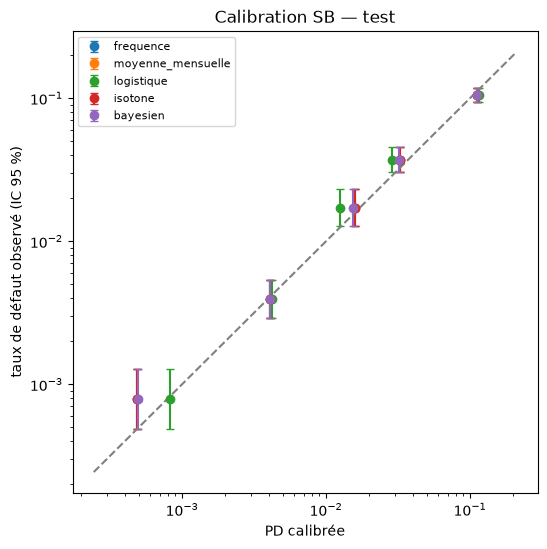

In [3]:
# Cellule 3 — vérification de chaque méthode sur le test
verifications = {}
for seg in SEGMENTS:
    test_s = base.filter((pl.col("segment") == seg) & (pl.col("echantillon") == "test"))
    globaux, par_classe = calibrage.verifier_calibrage(test_s, tables_calibrage[seg], TARGET)
    verifications[seg] = (globaux, par_classe)
    print(f"=== {seg} — Brier et décomposition de Murphy (test)"); print(globaux)
    print(par_classe)
    calibrage.diagramme_calibration(par_classe, calibrage.METHODES_CALIBRAGE, f"Calibration {seg} — test"); plt.show()

## 4.3 Méthode retenue et PD de meilleure estimation

La méthode retenue est celle dont la **fiabilité** sur le test est la meilleure (plus faible), sous réserve qu'aucune classe ne soit rejetée par le test de Jeffreys. Une fois la méthode choisie, la PD de chaque classe est **réestimée sur l'ensemble des données** (apprentissage et test) : le calibrage porte sur des niveaux de risque et non sur le classement, et utiliser tous les défauts réduit l'erreur d'estimation.

In [4]:
# Cellule 4 — choix de la méthode (meilleure fiabilité sur le test) et réestimation sur l'ensemble des données
METHODE = {}
tables_finales = {}
for seg in SEGMENTS:
    globaux, par_classe = verifications[seg]
    rejets = {m: int((par_classe[f"p_jeffreys_{m}"] < 0.05).sum()) for m in calibrage.METHODES_CALIBRAGE}
    eligibles = globaux.filter(pl.col("methode").is_in([m for m, r in rejets.items() if r == 0]))
    METHODE[seg] = (eligibles if eligibles.height else globaux).sort("fiabilite")["methode"][0]
    tables_finales[seg] = calibrage.pd_par_methode(base.filter(pl.col("segment") == seg), TARGET, DATE, poids_prior=1000)
    print(f"{seg} : méthode retenue = {METHODE[seg]} | classes rejetées par Jeffreys (test) : {rejets}")

SB : méthode retenue = frequence | classes rejetées par Jeffreys (test) : {'frequence': 1, 'moyenne_mensuelle': 1, 'logistique': 2, 'isotone': 1, 'bayesien': 1}


## 4.4 LRA, marge de prudence et PD réglementaire (8.4, 8.7)

**Long Run Average.** La PD réglementaire doit refléter le taux de défaut moyen sur un cycle économique complet (au moins cinq ans). La base ne couvre qu'**une seule année de défauts** (observations de janvier à avril 2021, défaut à 12 mois), en période Covid : la LRA n'est pas estimable sur les données. Hypothèse retenue : le taux observé sur la période est la meilleure estimation disponible du niveau moyen, et l'insuffisance des données est couverte par une marge de prudence.

**Marge de prudence (MoC).** Les orientations de l'EBA distinguent trois catégories :
- **catégorie A** (insuffisances des données et des méthodes) : absence de cycle complet et hausse significative du taux de défaut en avril. Elle est quantifiée par l'écart relatif entre le taux du **mois le plus défavorable** et le taux moyen du segment, appliqué à toutes les classes ;
- **catégorie B** (changements de contexte, de politique de crédit ou de processus) : aucun changement identifié sur la période ; sans objet ;
- **catégorie C** (erreur d'estimation générale) : écart entre le **quantile à 90 % de la loi a posteriori de Jeffreys** et la PD estimée, classe par classe ; elle est d'autant plus forte que la classe compte peu de défauts.

**PD finale** = PD estimée × (1 + MoC A) + MoC C, avec le **plancher réglementaire de 0,05 %** applicable à la clientèle de détail, et une PD non décroissante d'une classe à la suivante.

In [5]:
# Cellule 5 — MoC et PD réglementaire par segment et par classe
NIVEAU_MOC_C, PLANCHER = 0.90, 0.0005
pd_finales = []
for seg in SEGMENTS:
    moc_a = calibrage.moc_a_cycle(base.filter(pl.col("segment") == seg), TARGET, DATE)
    t = calibrage.pd_reglementaire(tables_finales[seg], METHODE[seg], moc_a["moc_a_relative"], NIVEAU_MOC_C, PLANCHER)
    pd_finales.append(t.with_columns(segment=pl.lit(seg), methode=pl.lit(METHODE[seg])))
    print(f"=== {seg} — taux par mois : { {k: round(v, 5) for k, v in moc_a['taux_par_mois'].items()} }")
    print(f"MoC A relative = {moc_a['moc_a_relative']:.1%} (pire mois {moc_a['taux_pire_mois']:.3%} / moyenne {moc_a['taux_moyen']:.3%})")
    print(t)
pd_finales = pl.concat(pd_finales)

=== SB — taux par mois : {'2021-01-01': 0.01187, '2021-02-01': 0.01254, '2021-03-01': 0.01258, '2021-04-01': 0.01232}
MoC A relative = 2.0% (pire mois 1.258% / moyenne 1.233%)
shape: (5, 8)
┌─────┬───────┬──────────┬────────────┬──────────┬──────────┬───────────────────┬───────────┐
│ chr ┆ n     ┆ n_defaut ┆ pd_estimee ┆ moc_a    ┆ moc_c    ┆ pd_avant_plancher ┆ pd_finale │
╞═════╪═══════╪══════════╪════════════╪══════════╪══════════╪═══════════════════╪═══════════╡
│ 1   ┆ 67430 ┆ 39.0     ┆ 0.000578   ┆ 0.000012 ┆ 0.00013  ┆ 0.00072           ┆ 0.00072   │
│ 2   ┆ 33796 ┆ 137.0    ┆ 0.004054   ┆ 0.000082 ┆ 0.000464 ┆ 0.0046            ┆ 0.0046    │
│ 3   ┆ 8336  ┆ 136.0    ┆ 0.016315   ┆ 0.000329 ┆ 0.001862 ┆ 0.018506          ┆ 0.018506  │
│ 4   ┆ 8250  ┆ 281.0    ┆ 0.034061   ┆ 0.000687 ┆ 0.002641 ┆ 0.037388          ┆ 0.037388  │
│ 5   ┆ 8813  ┆ 968.0    ┆ 0.109838   ┆ 0.002216 ┆ 0.004332 ┆ 0.116385          ┆ 0.116385  │
└─────┴───────┴──────────┴────────────┴──────────┴────────

## 4.5 Échelle maître (7.5)

L'échelle maître est une grille de grades commune à tous les segments, définie par des bornes de PD : la PD double d'un grade au suivant, à partir du plancher de 0,05 %. Chaque CHR de chaque segment est rattachée au grade qui contient sa PD finale. Elle permet de comparer et d'agréger des clients de segments différents sur une même échelle de risque ; avec un seul segment, c'est une simple projection, qui prendra tout son sens avec SA et SM.

In [6]:
# Cellule 6 — rattachement des CHR à l'échelle maître
echelle = calibrage.echelle_maitre()
pd_finales = pd_finales.with_columns(grade=pl.Series(calibrage.affecter_grade(pd_finales["pd_finale"])))
print(echelle)
pd_finales.select("segment", "chr", "n", "n_defaut", "methode", "pd_estimee", "moc_a", "moc_c", "pd_finale", "grade")

shape: (11, 3)
┌───────┬────────┬────────┐
│ grade ┆ pd_min ┆ pd_max │
╞═══════╪════════╪════════╡
│ 1     ┆ 0.0    ┆ 0.0005 │
│ 2     ┆ 0.0005 ┆ 0.001  │
│ 3     ┆ 0.001  ┆ 0.002  │
│ 4     ┆ 0.002  ┆ 0.004  │
│ 5     ┆ 0.004  ┆ 0.008  │
│ 6     ┆ 0.008  ┆ 0.016  │
│ 7     ┆ 0.016  ┆ 0.032  │
│ 8     ┆ 0.032  ┆ 0.064  │
│ 9     ┆ 0.064  ┆ 0.128  │
│ 10    ┆ 0.128  ┆ 0.256  │
│ 11    ┆ 0.256  ┆ 1.0    │
└───────┴────────┴────────┘


segment,chr,n,n_defaut,methode,pd_estimee,moc_a,moc_c,pd_finale,grade
"""SB""",1,67430,39.0,"""frequence""",0.000578,0.000012,0.00013,0.00072,2
"""SB""",2,33796,137.0,"""frequence""",0.004054,0.000082,0.000464,0.0046,5
"""SB""",3,8336,136.0,"""frequence""",0.016315,0.000329,0.001862,0.018506,7
"""SB""",4,8250,281.0,"""frequence""",0.034061,0.000687,0.002641,0.037388,8
"""SB""",5,8813,968.0,"""frequence""",0.109838,0.002216,0.004332,0.116385,9


## 4.6 Export

Les PD finales par segment et par classe, le détail des méthodes de calibrage et des vérifications sont exportés pour le dossier de validation.

In [7]:
# Cellule 7 — export
feuilles = {"PD_finales": pd_finales, "Echelle_maitre": echelle}
for seg in SEGMENTS:
    feuilles[f"{seg}_Calibrage_train"] = tables_calibrage[seg]
    feuilles[f"{seg}_Verif_globale"] = verifications[seg][0]
    feuilles[f"{seg}_Verif_classes"] = verifications[seg][1]
exploration.exporter_excel(feuilles, "outputs/quantification/pd_finales.xlsx")
pd_finales.write_parquet("outputs/quantification/pd_finales.parquet")
print("export : outputs/quantification/pd_finales.xlsx")

export : outputs/quantification/pd_finales.xlsx
